# BÀI THỰC HÀNH TUẦN 2 - P1: NỀN TẢNG DATA MINING

**Họ và tên:** Hoàng Ngọc Dung  
**MSSV:** 23139006

Notebook này hoàn thành toàn bộ checklist của tài liệu: hai bảng 5V, phân loại 8 bài toán, 6 mini-lab, phần mở rộng trên dữ liệu thật UCI Iris và phân tích Bonferroni ở quy mô $10^9$ người.

> Các số liệu về hệ thống gọi xe và IoT là giả định minh họa để phục vụ bài tập, không phải số liệu công bố của một doanh nghiệp cụ thể.

In [1]:
# Thư viện dùng xuyên suốt notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(suppress=True)

## 1. Phân tích 5V

### 1.1. Case study: nền tảng gọi xe/giao đồ ăn

Giả định hệ thống xử lý **3 triệu chuyến/đơn mỗi ngày**, mỗi chuyến dài trung bình **30 phút**, GPS gửi mỗi **3 giây**. Khi đó mỗi chuyến sinh khoảng $30\times60/3=600$ bản ghi GPS, tương đương **1,8 tỷ bản ghi vị trí/ngày**. Với 120 byte/bản ghi, riêng GPS khoảng **216 GB/ngày** trước sao lưu.

| V | Phân tích có số liệu/ví dụ cụ thể |
|---|---|
| **Volume** | 3 triệu đơn/ngày; khoảng 1,8 tỷ GPS records/ngày; xấp xỉ 216 GB/ngày chỉ cho GPS. Cần lưu trữ phân tán, phân vùng theo ngày/khu vực và định dạng cột; một CSDL quan hệ đơn lẻ sẽ khó mở rộng và dễ thành điểm nghẽn. |
| **Velocity** | Trung bình khoảng 20.800 GPS events/giây, giờ cao điểm có thể trên 60.000 events/giây. Ghép tài xế-khách cần dưới 1-2 giây; kiểm tra gian lận thanh toán cần gần thời gian thực. Dùng streaming, hàng đợi sự kiện và xử lý trạng thái. |
| **Variety** | GPS/time-series; đơn hàng và thanh toán dạng bảng; JSON log; bình luận văn bản; ảnh món ăn/giấy tờ; bản đồ/đồ thị đường đi; sự kiện clickstream. |
| **Veracity** | GPS nhiễu/trôi trong hẻm hoặc khu cao tầng; trùng/mất sự kiện; địa chỉ sai; đánh giá ảo; giao dịch gian lận. Khắc phục bằng kiểm tra miền giá trị, loại trùng theo event ID, watermark, đối chiếu nhiều nguồn và mô hình phát hiện bất thường. |
| **Value** | Ghép xe và tối ưu tuyến đường giúp giảm thời gian chờ; định giá động theo cung-cầu; gợi ý món/khuyến mãi; dự báo nhu cầu theo khu vực; phát hiện gian lận và đánh giá ảo. |

### 1.2. Hệ thống tự chọn: IoT nông nghiệp thông minh

Phạm vi giả định: **100 trang trại**, tổng **5.000 nút cảm biến**, mỗi nút đo 4 đại lượng sau mỗi 10 giây; **200 camera** chụp 1 ảnh/5 phút. Mỗi bản ghi cảm biến khoảng 200 byte, mỗi ảnh khoảng 150 KB.

| V | Phân tích có số liệu/ví dụ cụ thể |
|---|---|
| **Volume** | 43,2 triệu bản ghi cảm biến/ngày (=5.000×8.640), chứa 172,8 triệu giá trị đo; khoảng 8,64 GB/ngày. Camera sinh 57.600 ảnh/ngày, thêm khoảng 8,64 GB/ngày. Tổng thô xấp xỉ 17,28 GB/ngày hay 6,31 TB/năm trước replication. |
| **Velocity** | Trung bình 500 records/giây; cảnh báo đất quá khô, nhiệt độ cao hoặc bơm hỏng cần dưới 3 giây. Dashboard chấp nhận cập nhật 5-10 giây; huấn luyện dự báo năng suất có thể chạy theo lô hằng ngày/tuần. |
| **Variety** | Chuỗi thời gian số; JSON/MQTT log; ảnh lá/cây; ảnh drone; CSV thời tiết; metadata thiết bị và lịch sử tưới/bón phân. |
| **Veracity** | Cảm biến trôi chuẩn, pin yếu, gói tin mất/trùng/đến sai thứ tự; ảnh mờ hoặc thiếu sáng; timestamp lệch. Khắc phục bằng hiệu chuẩn định kỳ, kiểm tra range/rate-of-change, event ID, watermark, cảm biến dự phòng và quality flag. |
| **Value** | Điều khiển tưới theo nhu cầu để giảm lãng phí nước; Classification phát hiện bệnh; Regression dự báo độ ẩm/năng suất; Clustering chia vùng canh tác; Association Rules tìm quan hệ giữa thời tiết-tưới-bệnh. |

**Kết luận:** Hệ thống cần xử lý kết hợp streaming và batch. Giá trị cốt lõi không nằm ở việc lưu nhiều dữ liệu, mà ở quyết định tưới, cảnh báo và dự báo được tạo ra đúng lúc.

In [2]:
# Kiểm tra phép ước lượng Volume cho hệ thống IoT
n_farms = 100
n_sensor_nodes = 5_000
n_values_per_record = 4
interval_seconds = 10
record_bytes = 200
n_cameras = 200
image_interval_minutes = 5
image_kb = 150

records_per_day = n_sensor_nodes * 86_400 // interval_seconds
values_per_day = records_per_day * n_values_per_record
sensor_gb_day = records_per_day * record_bytes / 1e9
images_per_day = n_cameras * 24 * 60 // image_interval_minutes
image_gb_day = images_per_day * image_kb * 1_000 / 1e9
total_tb_year = (sensor_gb_day + image_gb_day) * 365 / 1_000

pd.DataFrame({
    "Chỉ số": ["Bản ghi cảm biến/ngày", "Giá trị đo/ngày", "Ảnh/ngày", "Dữ liệu thô/ngày (GB)", "Dữ liệu thô/năm (TB)"],
    "Ước lượng": [records_per_day, values_per_day, images_per_day, round(sensor_gb_day + image_gb_day, 2), round(total_tb_year, 2)]
})

,Chỉ số,Ước lượng
0,Bản ghi cảm biến/ngày,4.320000e+07
1,Giá trị đo/ngày,1.728000e+08
2,Ảnh/ngày,5.760000e+04
3,Dữ liệu thô/ngày (GB),1.728000e+01
4,Dữ liệu thô/năm (TB),6.310000e+00


## 2. Nhận diện và phân loại 8 bài toán khai phá dữ liệu

| # | Kỹ thuật | Đặc điểm dữ liệu | Mô hình tính toán phù hợp | Lý do ngắn gọn |
|---:|---|---|---|---|
| 1 | Classification | Có nhãn nhị phân mắc/không mắc | Single-machine; MapReduce/Spark khi dữ liệu rất lớn | Đầu ra là một trong hai lớp. |
| 2 | Distinct counting (HyperLogLog/Flajolet-Martin) | Luồng vô hạn 24/7, cần bộ nhớ nhỏ | Streams/xác suất | Không thể lưu toàn bộ truy vấn để đếm chính xác ở quy mô lớn. |
| 3 | Clustering văn bản | Không nhãn; vector TF-IDF/embedding thưa, nhiều chiều | Single-machine nhỏ; MapReduce/Spark lớn | Không biết trước chủ đề, cần tự tìm nhóm tương đồng. |
| 4 | Association Rules | Dữ liệu giỏ hàng, tập item | A-Priori/FP-Growth; Spark khi lớn | Tìm tập phổ biến và luật A⇒B. |
| 5 | Regression/time-series forecasting | Có nhãn là giá thực tế; dữ liệu theo thời gian | Single-machine; streams nếu cập nhật liên tục | Giá là đại lượng số liên tục; phải chia train/test theo thời gian để tránh leakage. |
| 6 | Classification online | Có nhãn gian lận; luồng giao dịch liên tục; mất cân bằng lớp | Streams/online inference | Phải chấm điểm ngay khi giao dịch tới, tối ưu precision-recall chứ không chỉ accuracy. |
| 7 | Graph clustering/community detection | Đồ thị rất lớn, hàng trăm triệu đỉnh/cạnh | Xử lý đồ thị phân tán/MapReduce | Cộng đồng là nhóm đỉnh liên kết dày hơn bên trong. |
| 8 | Ordinal Classification hoặc Regression | Có nhãn 1-5 sao | Single-machine; Spark khi lớn | 1-5 là lớp có thứ tự; có thể hồi quy nếu coi điểm là số liên tục rồi làm tròn/chặn miền. |

## 3. Sáu mini-lab Python

### Lab 1 - TF-IDF

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

docs = [
    "big data can duoc xu ly phan tan",
    "spark xu ly du lieu lon theo lo",
    "kafka xu ly du lieu thoi gian thuc",
]

vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(docs)
tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=vectorizer.get_feature_names_out())
tfidf_df.round(3)

,big,can,data,du,duoc,gian,kafka,lieu,lo,lon,ly,phan,spark,tan,theo,thoi,thuc,xu
0,0.386,0.386,0.386,0.000,0.386,0.000,0.000,0.000,0.000,0.000,0.228,0.386,0.000,0.386,0.000,0.000,0.000,0.228
1,0.000,0.000,0.000,0.314,0.000,0.000,0.000,0.314,0.413,0.413,0.244,0.000,0.413,0.000,0.413,0.000,0.000,0.244
2,0.000,0.000,0.000,0.314,0.000,0.413,0.413,0.314,0.000,0.000,0.244,0.000,0.000,0.000,0.000,0.413,0.413,0.244


**Nhận xét:** `xu` và `ly` xuất hiện trong cả ba văn bản nên IDF nhỏ và điểm TF-IDF thấp hơn các từ chỉ xuất hiện ở một văn bản như `kafka`, `spark`, `big`. Lưu ý mã mẫu tách `xu ly` thành hai token, không phải một token `xu_ly`; nếu muốn giữ cụm từ, cần nối bằng dấu gạch dưới hoặc dùng n-gram.

### Lab 2 - Mô phỏng nguyên lý Bonferroni

In [4]:
import random
from collections import defaultdict

def bonferroni_simulation(n_people=2_000, n_hotels=50, n_days=30, p_visit=0.3, seed=42):
    rng = random.Random(seed)
    by_hotel_day = defaultdict(list)
    for day in range(n_days):
        for person in range(n_people):
            if rng.random() < p_visit:
                hotel = rng.randrange(n_hotels)
                by_hotel_day[(hotel, day)].append(person)

    pair_days = defaultdict(set)
    for (hotel, day), people in by_hotel_day.items():
        for i in range(len(people)):
            for j in range(i + 1, len(people)):
                pair_days[(people[i], people[j])].add(day)

    suspects = sum(len(days) >= 2 for days in pair_days.values())
    return suspects, len(pair_days)

suspects, observed_pairs = bonferroni_simulation()
print("Số cặp 'khả nghi' (dữ liệu hoàn toàn ngẫu nhiên):", suspects)
print("Số cặp từng gặp ít nhất một lần:", observed_pairs)

Số cặp 'khả nghi' (dữ liệu hoàn toàn ngẫu nhiên): 2796
Số cặp từng gặp ít nhất một lần: 105316


,N_PEOPLE,N_DAYS,Cặp đã gặp,Cặp khả nghi
0,500,15,3322,30
1,1000,15,13357,157
2,2000,15,52560,712
3,2000,30,105316,2796
4,3000,30,236487,6055


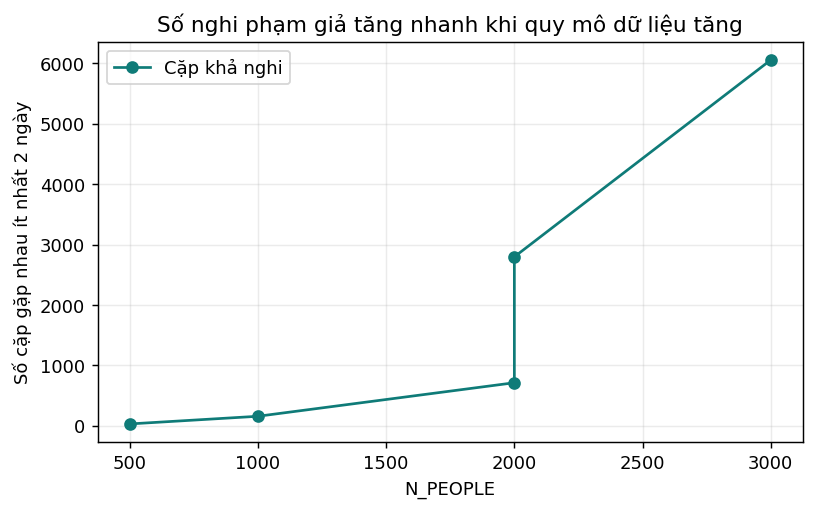

In [5]:
# Thử thay đổi quy mô; giữ seed để kết quả tái lập
experiments = []
for n_people, n_days in [(500, 15), (1_000, 15), (2_000, 15), (2_000, 30), (3_000, 30)]:
    suspects, observed = bonferroni_simulation(n_people=n_people, n_days=n_days)
    experiments.append([n_people, n_days, observed, suspects])

bonferroni_df = pd.DataFrame(experiments, columns=["N_PEOPLE", "N_DAYS", "Cặp đã gặp", "Cặp khả nghi"])
display(bonferroni_df)

ax = bonferroni_df.plot(x="N_PEOPLE", y="Cặp khả nghi", marker="o", figsize=(7, 4), color="#0F7B78")
ax.set_title("Số nghi phạm giả tăng nhanh khi quy mô dữ liệu tăng")
ax.set_ylabel("Số cặp gặp nhau ít nhất 2 ngày")
ax.grid(alpha=0.25)
plt.show()

**Nhận xét:** Không hề cài một “kẻ xấu” nào, nhưng seed 42 vẫn tạo ra hàng nghìn cặp gặp nhau ít nhất hai ngày. Đây là multiple testing: số cặp người có thể kiểm tra tăng theo $\binom{N}{2}$, nên một xác suất ngẫu nhiên rất nhỏ vẫn tạo nhiều dương tính giả.

**Nếu tăng lên $10^9$ người:** với 50 khách sạn, 30 ngày, xác suất đi khách sạn 0,3, số người trung bình trong mỗi `(hotel, day)` là $10^9\times0,3/50=6$ triệu. Vòng lặp tạo cặp phải xét xấp xỉ $30\times50\times\binom{6\times10^6}{2}\approx2,7\times10^{16}$ cặp. Ngay cả tốc độ 1 triệu cặp/giây cũng cần khoảng **856 năm**, chưa kể bộ nhớ. MapReduce giúp chia theo `(hotel, day)` và tổng hợp theo cặp người, nhưng vẫn cần pruning/approximation (lọc trước, sketch, sampling hoặc ngưỡng hỗ trợ) để tránh bùng nổ ứng viên.

### Lab 3 - Clustering với K-Means

In [6]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np

khach_hang = np.array([
    [2, 150], [3, 180], [1, 120],
    [15, 90], [18, 100], [20, 85],
    [4, 900], [5, 1200], [3, 1000],
])

# Chạy đúng mã mẫu
raw_model = KMeans(n_clusters=3, random_state=42, n_init=10)
raw_labels = raw_model.fit_predict(khach_hang)
print("Nhãn cụm khi chưa chuẩn hóa:", raw_labels)
print("Tâm cụm khi chưa chuẩn hóa:\n", raw_model.cluster_centers_.round(1))

# Sửa điểm yếu của mã mẫu: chuẩn hóa vì hai thuộc tính khác thang đo
scaler = StandardScaler()
scaled = scaler.fit_transform(khach_hang)
scaled_model = KMeans(n_clusters=3, random_state=42, n_init=10)
scaled_labels = scaled_model.fit_predict(scaled)
centers_original_scale = scaler.inverse_transform(scaled_model.cluster_centers_)
print("\nNhãn cụm sau chuẩn hóa:", scaled_labels)
print("Tâm cụm quy về thang đo gốc:\n", centers_original_scale.round(1))

Nhãn cụm khi chưa chuẩn hóa: [1 1 1 1 1 1 2 0 2]
Tâm cụm khi chưa chuẩn hóa:
 [[   5.  1200. ]
 [   9.8  120.8]
 [   3.5  950. ]]

Nhãn cụm sau chuẩn hóa: [2 2 2 0 0 0 1 1 1]
Tâm cụm quy về thang đo gốc:
 [[  17.7   91.7]
 [   4.  1033.3]
 [   2.   150. ]]


**Phát hiện quan trọng:** chạy nguyên mã trong slide không tạo đúng ba nhóm kỳ vọng vì “giá trị đơn” (85-1200) lấn át “số đơn” (1-20) trong khoảng cách Euclid. Sau `StandardScaler`, ba cụm đúng trực giác: mua nhiều-giá trị thấp; mua ít-giá trị cao; mua ít-giá trị thấp. Đây là bước tiền xử lý cần ghi vào báo cáo.

### Lab 4 - Association Rules thủ công

In [7]:
gio_hang = [
    {"Bim", "Bia", "Sua"},
    {"Bim", "Bia"},
    {"Bim", "Bia", "Banh"},
    {"Sua", "Banh"},
]

def support(itemset, baskets=gio_hang):
    return sum(itemset.issubset(b) for b in baskets) / len(baskets)

def confidence(A, B, baskets=gio_hang):
    return support(A | B, baskets) / support(A, baskets)

def lift(A, B, baskets=gio_hang):
    return confidence(A, B, baskets) / support(B, baskets)

rules = []
for A, B in [({"Bim"}, {"Bia"}), ({"Banh"}, {"Sua"})]:
    rules.append({
        "Luật": f"{next(iter(A))} => {next(iter(B))}",
        "Support": support(A | B),
        "Confidence": confidence(A, B),
        "Lift": lift(A, B),
    })
pd.DataFrame(rules).round(3)

,Luật,Support,Confidence,Lift
0,Bim => Bia,0.75,1.0,1.333
1,Banh => Sua,0.25,0.5,1.000


**Kết luận:** `Bim ⇒ Bia` mạnh hơn trong dữ liệu này (support 0,75; confidence 1,00; lift 1,33). `Banh ⇒ Sua` chỉ có support 0,25; confidence 0,50; lift 1,00, nghĩa là không cải thiện xác suất mua sữa so với mức nền.

### Lab 5 - Classification với Decision Tree

Độ chính xác trên tập test: 1.0
Dự đoán cho [6 giờ học, 85% điểm danh]: 1


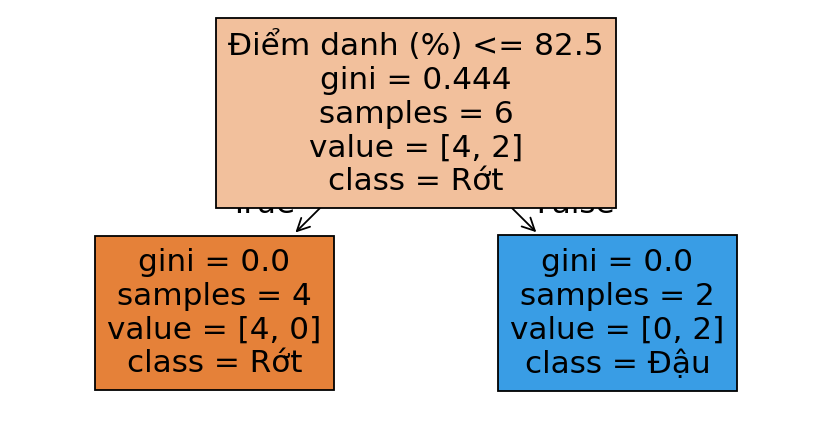

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

X_student = np.array([[2,60],[3,70],[8,95],[1,50],[9,98],[4,75],[7,90],[2,55]])
y_student = np.array([0,0,1,0,1,0,1,0])

X_train, X_test, y_train, y_test = train_test_split(
    X_student, y_student, test_size=0.25, random_state=1
)
clf = DecisionTreeClassifier(max_depth=3, random_state=1)
clf.fit(X_train, y_train)

print("Độ chính xác trên tập test:", clf.score(X_test, y_test))
print("Dự đoán cho [6 giờ học, 85% điểm danh]:", clf.predict([[6, 85]])[0])

plt.figure(figsize=(8, 4))
plot_tree(clf, feature_names=["Giờ học/tuần", "Điểm danh (%)"], class_names=["Rớt", "Đậu"], filled=True)
plt.show()

**Nhận xét:** mô hình đạt 1,00 trên đúng 2 mẫu test và dự đoán sinh viên `[6, 85]` là đậu. Tuy nhiên 2 mẫu là quá ít để kết luận mô hình tổng quát tốt; cần thêm dữ liệu và cross-validation.

### Lab 6 - Regression với Linear Regression

In [9]:
from sklearn.linear_model import LinearRegression

X_ad = np.array([[10],[20],[30],[40],[50],[60]])
y_revenue = np.array([120, 210, 300, 405, 500, 590])

reg = LinearRegression()
reg.fit(X_ad, y_revenue)

print(f"beta_0 (intercept) = {reg.intercept_:.2f}")
print(f"beta_1 (hệ số)     = {reg.coef_[0]:.2f}")
print(f"Dự đoán doanh thu khi chi 45 triệu quảng cáo: {reg.predict([[45]])[0]:.2f} triệu VND")
print(f"R² trên toàn bộ 6 điểm: {reg.score(X_ad, y_revenue):.4f}")

beta_0 (intercept) = 21.67
beta_1 (hệ số)     = 9.50
Dự đoán doanh thu khi chi 45 triệu quảng cáo: 449.17 triệu VND
R² trên toàn bộ 6 điểm: 0.9995


Mô hình thu được $\hat y=21,67+9,50x$. Khi chi 45 triệu đồng quảng cáo, doanh thu dự đoán là **449,17 triệu đồng**. R² cao vì dữ liệu giả định gần tuyến tính, nhưng không chứng minh quan hệ nhân quả.

## 4. Mở rộng Lab 3-6 trên dữ liệu thật UCI Iris

In [10]:
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, silhouette_score,
    mean_absolute_error, mean_squared_error, r2_score
)

iris = load_iris(as_frame=True)
iris_df = iris.frame.copy()
print("Kích thước:", iris_df.shape)
print("Thuộc tính:", list(iris.feature_names))
print("Số mẫu mỗi loài:", iris_df["target"].value_counts().sort_index().to_dict())
iris_df.head()

Kích thước: (150, 5)
Thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Số mẫu mỗi loài: {0: 50, 1: 50, 2: 50}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### 4.1. Clustering: K-Means trên 150 mẫu Iris

Silhouette score: 0.460
Adjusted Rand Index (chỉ để đánh giá với nhãn loài): 0.620
Kích thước các cụm: [53 50 47]


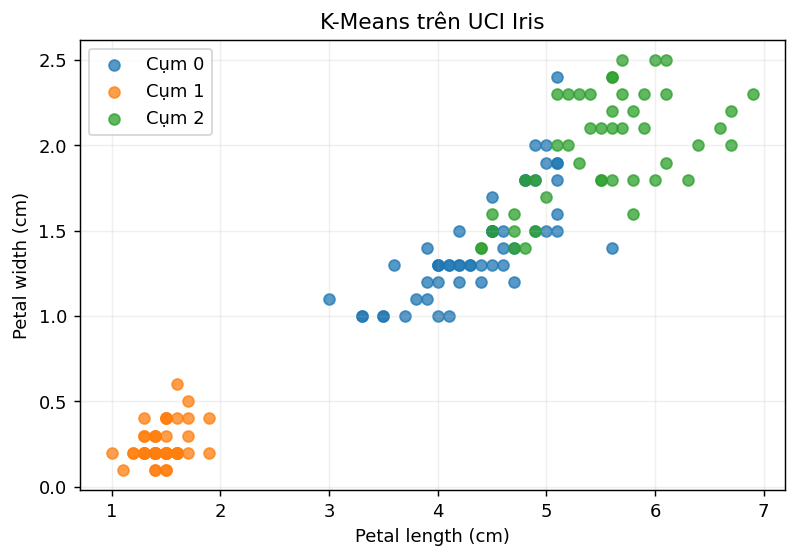

In [11]:
iris_X = iris.data
iris_y = iris.target
iris_scaler = StandardScaler()
iris_scaled = iris_scaler.fit_transform(iris_X)

iris_km = KMeans(n_clusters=3, random_state=42, n_init=20)
iris_clusters = iris_km.fit_predict(iris_scaled)
print(f"Silhouette score: {silhouette_score(iris_scaled, iris_clusters):.3f}")
print(f"Adjusted Rand Index (chỉ để đánh giá với nhãn loài): {adjusted_rand_score(iris_y, iris_clusters):.3f}")
print("Kích thước các cụm:", np.bincount(iris_clusters))

plt.figure(figsize=(7, 4.5))
for c in range(3):
    mask = iris_clusters == c
    plt.scatter(iris_X.iloc[mask, 2], iris_X.iloc[mask, 3], label=f"Cụm {c}", alpha=0.75)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("K-Means trên UCI Iris")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 4.2. Association Rules: rời rạc hóa Iris thành giao dịch

In [12]:
# Mỗi mẫu hoa trở thành một giao dịch gồm 4 mức đo và tên loài.
bands = pd.DataFrame(index=iris_df.index)
for col in iris.feature_names:
    bands[col] = pd.qcut(iris_df[col], q=3, labels=["low", "medium", "high"], duplicates="drop").astype(str)

transactions = []
for i, row in bands.iterrows():
    items = {f"{col}={row[col]}" for col in iris.feature_names}
    items.add(f"species={iris.target_names[int(iris_y.iloc[i])]}")
    transactions.append(items)

def tx_support(items):
    items = set(items)
    return sum(items.issubset(t) for t in transactions) / len(transactions)

feature_items = sorted({item for t in transactions for item in t if not item.startswith("species=")})
species_items = [f"species={name}" for name in iris.target_names]
uci_rules = []
for A in feature_items:
    for B in species_items:
        support_ab = tx_support({A, B})
        if support_ab >= 0.10:
            conf = support_ab / tx_support({A})
            rule_lift = conf / tx_support({B})
            uci_rules.append([A, B, support_ab, conf, rule_lift])

uci_rules_df = pd.DataFrame(uci_rules, columns=["Antecedent", "Consequent", "Support", "Confidence", "Lift"])
uci_rules_df.sort_values(["Confidence", "Support"], ascending=False).head(8).round(3)

,Antecedent,Consequent,Support,Confidence,Lift
1,petal length (cm)=low,species=setosa,0.333,1.000,3.000
4,petal width (cm)=low,species=setosa,0.333,1.000,3.000
3,petal width (cm)=high,species=virginica,0.307,0.958,2.875
0,petal length (cm)=high,species=virginica,0.293,0.957,2.870
5,petal width (cm)=medium,species=versicolor,0.320,0.923,2.769
2,petal length (cm)=medium,species=versicolor,0.320,0.889,2.667
7,sepal length (cm)=low,species=setosa,0.300,0.865,2.596
10,sepal width (cm)=high,species=setosa,0.220,0.767,2.302


Hai luật mạnh nhất là `petal length=low ⇒ setosa` và `petal width=low ⇒ setosa`, đều có confidence 1,00 và lift 3,00.

### 4.3. Classification: Decision Tree dự đoán loài

Accuracy trên 30 mẫu test: 0.967


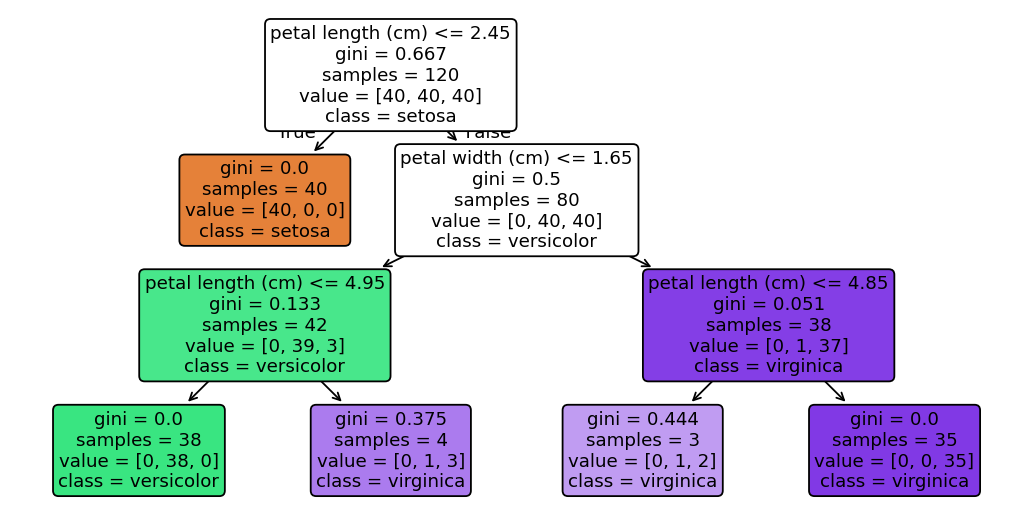

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    iris_X, iris_y, test_size=0.20, random_state=42, stratify=iris_y
)
iris_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
iris_tree.fit(X_train, y_train)
iris_pred = iris_tree.predict(X_test)
print(f"Accuracy trên 30 mẫu test: {accuracy_score(y_test, iris_pred):.3f}")

plt.figure(figsize=(10, 5))
plot_tree(iris_tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, rounded=True)
plt.show()

### 4.4. Regression: dự đoán sepal length

MAE = 0.234 cm
RMSE = 0.320 cm
R² = 0.852


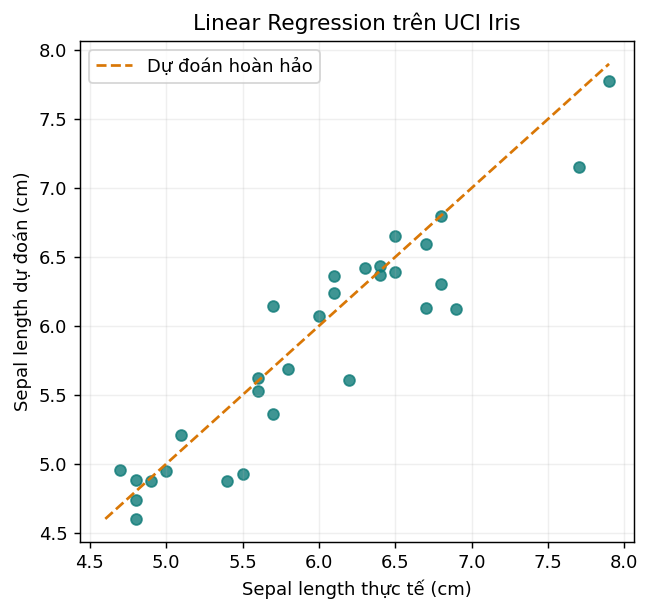

In [14]:
reg_X = iris_df.drop(columns=["sepal length (cm)", "target"])
reg_y = iris_df["sepal length (cm)"]
X_train, X_test, y_train, y_test = train_test_split(reg_X, reg_y, test_size=0.20, random_state=42)
iris_reg = LinearRegression().fit(X_train, y_train)
reg_pred = iris_reg.predict(X_test)

mae = mean_absolute_error(y_test, reg_pred)
rmse = mean_squared_error(y_test, reg_pred) ** 0.5
r2 = r2_score(y_test, reg_pred)
print(f"MAE = {mae:.3f} cm")
print(f"RMSE = {rmse:.3f} cm")
print(f"R² = {r2:.3f}")

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, reg_pred, color="#0F7B78", alpha=0.8)
low, high = min(y_test.min(), reg_pred.min()), max(y_test.max(), reg_pred.max())
plt.plot([low, high], [low, high], "--", color="#D97706", label="Dự đoán hoàn hảo")
plt.xlabel("Sepal length thực tế (cm)")
plt.ylabel("Sepal length dự đoán (cm)")
plt.title("Linear Regression trên UCI Iris")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. Checklist hoàn thành

- [x] Bảng 5V cho case study gọi xe/giao đồ ăn.
- [x] Bảng 5V cho hệ thống tự chọn IoT nông nghiệp thông minh.
- [x] Phân loại đủ 8/8 bài toán theo kỹ thuật - dữ liệu - mô hình tính toán.
- [x] Chạy đủ 6 mini-lab, có output và giải thích.
- [x] Áp dụng Lab 3-6 trên dữ liệu thật UCI Iris.
- [x] Ước lượng quy mô Bonferroni với $10^9$ người và giải thích nhu cầu MapReduce/pruning.

**Điểm cần nhớ khi trình bày:** K-Means trong mã mẫu cần chuẩn hóa; dương tính giả Bonferroni xuất hiện dù dữ liệu hoàn toàn ngẫu nhiên; và MapReduce giải quyết phân tán tính toán nhưng không tự loại bỏ bùng nổ tổ hợp.